### 集成学习
- **Bootstrap（自助采样）**
- **Aggregating（聚合）**

### Bagging思想 （Bootstrap Aggregating，自助聚合）
- 有放回的随机抽样
- 平权投票
- 并行执行

### Bagging思想 （Bootstrap Aggregating，自助聚合）
- 有放回的随机抽样
- 平权投票
- 并行执行

### 随机森林
基于Bagging思想实现的一种集成学习算法，采用CART决策树作为每一个基弱学习器
必须使用强学习器（深度很大的树，高方差模型）平均方差

**样本随机（行）**
有放回地从 原训练集 中抽取N个样本（N为训练集中样本总数），构建T个不同的子训练集。
（标准的Bootstrapg，约含63.2%原始数据，因会有大量重复抽到的样本）

*有放回随机抽样保证弱学习器上的样本有交集也有差异，更容易发挥投票表决效果
没有交际的样本训练出的每棵树都是有偏的，即有很大差异

**特征随机（列）**  随机森林的核心
在构建每一棵CART树的过程中，每一次分裂节点并不是从全部M个特征中取最优，而是先随机选取一小部分的m个特征（m《M）
再从这m个特征中选取最优

**聚合**
T棵树并行生长（一般不剪枝）
分类：平权投票（少数服从多数）
回归：取平均值

**特征随机的关键**
标准Bagging的缺点：
如果所有树都用全部特征分裂，则都会抢着用那个增益最大的特征，导致所有的树长得极其相似（相关性ρ极高）
而高相关性会严重拖累方差的下降速度



单棵决策树准确率: 0.922
随机森林 (Bagging) 准确率: 0.933


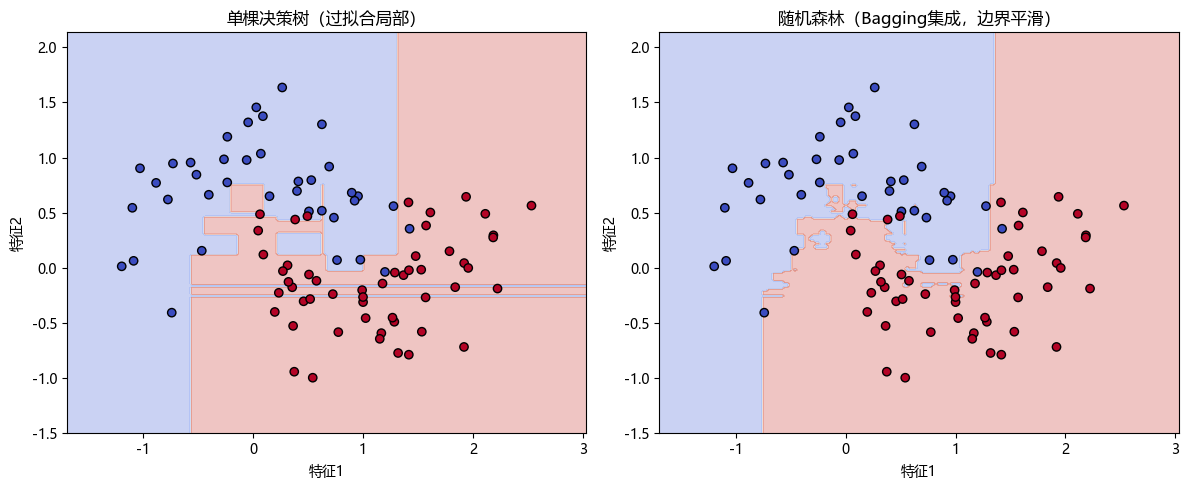

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

# 1. 生成非线性数据
X, y = make_moons(n_samples=300, noise=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. 单棵决策树（深度较大，作为强学习器）
tree = DecisionTreeClassifier(max_depth=10, random_state=42)
tree.fit(X_train, y_train)

# 3. 随机森林（Bagging + 特征随机）
rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42)
rf.fit(X_train, y_train)

# 4. 预测与评估
y_pred_tree = tree.predict(X_test)
y_pred_rf = rf.predict(X_test)

print(f"单棵决策树准确率: {accuracy_score(y_test, y_pred_tree):.3f}")
print(f"随机森林 (Bagging) 准确率: {accuracy_score(y_test, y_pred_rf):.3f}")

# 5. 可视化决策边界（直观对比）
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='coolwarm')
    plt.title(title)
    plt.xlabel("特征1")
    plt.ylabel("特征2")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plot_decision_boundary(tree, X_test, y_test, "单棵决策树（过拟合局部）")
plt.subplot(1, 2, 2)
plot_decision_boundary(rf, X_test, y_test, "随机森林（Bagging集成，边界平滑）")
plt.tight_layout()
plt.show()

## Boosting思想
必须用弱学习器（深度只有 1 层的树桩，即高偏差模型），因为要一步步纠正偏差。
串行训练，后一个模型的训练永远是在前一个模型的基础上完成


### Adaboost算法（自适应提升）
**初始化**
给训练集中N个样本分配相同的初始权重，通常为1/N

**训练弱分类器**
$$
α_t = \frac{1}{2}ln(\frac{1-ε_t}{ε_t})
$$
·ε是该弱学习器的错误率
基于当前的权重分布，训练一个弱学习器,如决策树桩(通常只有一层)
根据弱分类器在训练集上的分类错误率计算该弱分类器的权重

**更新训练集样本权重**
$$
D_{t+1}(i) = \frac{D_t(i)*e^{-α_t*y_i*h_t(x_i)}}{Z_t}
$$
- D_t(i)：本轮训练样本i的权重
- （$h_t(x_i)$）是本轮分类器对样本i的预测结果，（$y_i$）是该样本的真实标签
- 分类正确时（$y_i \cdot h_t(x_i) = 1$），指数部分变小，权重**下降**；
- 分类错误时（$y_i \cdot h_t(x_i) = -1$），指数部分增大，权重**上升**。
- （$Z_t$）为归一化值（所有样本权重总和）

根据错误率，在构造下一个训练集时，提高被分类错误样本的权重，降低正确样本的权重
用更新过的样本集去训练下一个分类器

**重复迭代训练**
不断重复训练弱学习器、计算弱学习器权重、更新数据权重分布的过程，直到训练出T个弱分类器

**加权集成**
训练得到T个弱分类器，及其对应权重集成一个强学习器
$$
H(x) = sign(\sum_{t=1}^Tα_th_t(x))
$$

### 梯度提升树（Gradient Boosting Decision Tree）
**算法思想**
根据拟合残差的思想进行提升
残差（Residual） =  真实值 - 预测值
GBDT使用CART回归树树作为弱学习器 （即使面对分类问题）

**初始化弱学习器**
用原始数据训练一个弱学习器（通常是一个常数模型），得到一个初步预测值$\hat{y}$使得初始损失最小
回归任务的损失函数 平方损失
$$
L(y,f(x)) = \frac{1}{2}\sum_{i=1}_n(y_i - f(x_i))^2
$$

$$
令\frac{∂L(y,f(x))}{∂f(x_i)} = -\sum_{i=1}_n(y_i - f(x_i)) = 0
$$
得到$f(x_i) = \frac{1}{n}\sum_{i=1}^ny_i$即初始化树桩为目标值的均值时，损失最小


**计算负梯度**
$$
g_{i,t} = -\frac{∂L(y_i,f_{t-1}(x_i))}{∂f_{t-1}(x_i)}
$$
样本i第t轮要拟合的伪残差$r_{ti} = g_{i,t}$，即负梯度
- 求导对象是上一轮的强学习器$f_{t-1}(x)$

**拟合CART回归树**
使用上一轮得到的伪残差，训练新的CART回归树，用以拟合当前模型的误差

**更新强学习器**
$$
f_t(xi) = f_{t-1}(xi) + αh_t(x_i)
$$
- α为学习率用来控制步长，防止过拟合，学习率过小可以使模型更加稳定，但需要更多的迭代次数
- $h_t(x)$是整棵树

**重复进行轮迭代**
最终的GBDT模型由多棵CART回归树组成，其预测结果是初始预测值（采用MSE时为均值）以及所有决策树预测结果的加权累加和（存在学习率α）

数据前5行：
   Area  Floor  Price
0  36.2     20  47.38
1  76.6     11  83.44
2  61.2     17  62.73
3  51.9      8  67.66
4  20.9      4  41.51

房价统计：最小值 24.8，最大值 88.1，均值 55.1

模型性能对比：
单棵浅决策树 (max_depth=2)  RMSE: 6.252  R²: 0.839
GBDT (100棵树, lr=0.1)       RMSE: 4.055  R²: 0.932


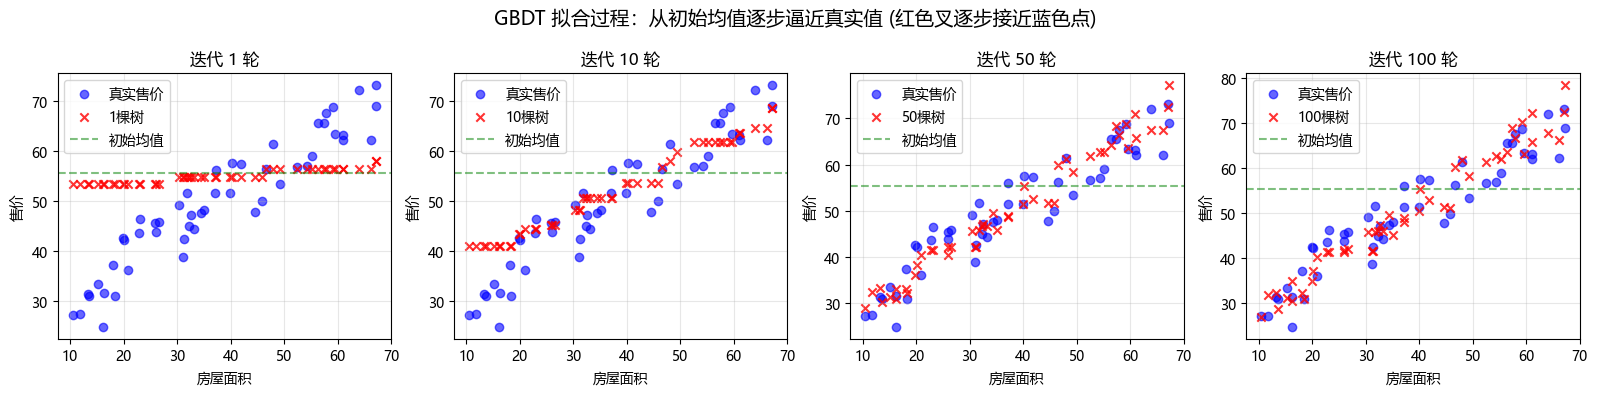


初始预测值（均值）: 55.450
第1棵树对测试样本1的预测贡献: -7.351
GBDT模型对该样本的最终预测值: 51.390
手动累加（前2棵树）验证: 54.379 (与最终值有差异，因为一共100棵)

特征重要性：
面积 (Area) 重要性: 0.978
楼层 (Floor) 重要性: 0.022


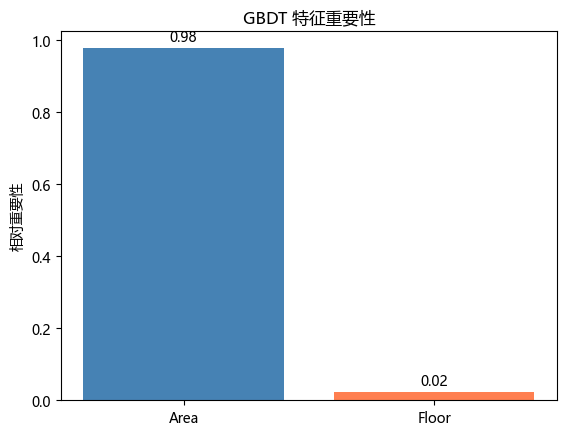

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

np.random.seed(42)
n_samples = 200

# 特征1：面积（10~80 平米）
area = np.random.uniform(10, 80, n_samples)
# 特征2：楼层（1~20 层）
floor = np.random.randint(1, 21, n_samples)

# 构造真实关系（非线性）：
# 基础价格 = 面积 * 0.8 + 楼层带来的正弦波动（好楼层贵）+ 随机噪声
price = 20 + area * 0.8 + 5 * np.sin(floor / 3) + np.random.normal(0, 3, n_samples)

price = np.maximum(price, 15)

# 构造DataFrame
df = pd.DataFrame({
    'Area': area.round(1),
    'Floor': floor,
    'Price': price.round(2)
})

# 划分特征和目标
X = df[['Area', 'Floor']].values
y = df['Price'].values

print("数据前5行：")
print(df.head())
print(f"\n房价统计：最小值 {y.min():.1f}，最大值 {y.max():.1f}，均值 {y.mean():.1f}")

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 1. 单棵浅决策树（深度2，作为弱学习器）
shallow_tree = DecisionTreeRegressor(max_depth=2, random_state=42)
shallow_tree.fit(X_train, y_train)
y_pred_tree = shallow_tree.predict(X_test)

# 2. GBDT 集成（100棵树，学习率0.1）
gbdt = GradientBoostingRegressor(
    n_estimators=100,      # 树的数量
    learning_rate=0.1,     # 步长（收缩率）
    max_depth=2,           # 每棵树都很浅（弱学习器）
    random_state=42
)
gbdt.fit(X_train, y_train)
y_pred_gbdt = gbdt.predict(X_test)

# 3. 评估指标对比
print("\n" + "="*50)
print("模型性能对比：")
print(f"单棵浅决策树 (max_depth=2)  RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_tree)):.3f}  R²: {r2_score(y_test, y_pred_tree):.3f}")
print(f"GBDT (100棵树, lr=0.1)       RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_gbdt)):.3f}  R²: {r2_score(y_test, y_pred_gbdt):.3f}")

# 取测试集的前 50 个样本按面积排序
sorted_idx = np.argsort(X_test[:, 0])[:50]
X_sorted = X_test[sorted_idx]
y_sorted = y_test[sorted_idx]

# 获取不同迭代阶段的预测值
staged_preds = list(gbdt.staged_predict(X_sorted))

# 绘制：第1棵、第10棵、第50棵、第100棵树的预测效果
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
stages_to_plot = [0, 9, 49, 99]  # 索引对应第1,10,50,100棵树

for ax, stage_idx in zip(axes, stages_to_plot):
    # 真实值
    ax.scatter(X_sorted[:, 0], y_sorted, alpha=0.6, label='真实售价', color='blue')
    # 当前阶段的预测值
    ax.scatter(X_sorted[:, 0], staged_preds[stage_idx], 
               alpha=0.8, label=f'{stage_idx+1}棵树', color='red', marker='x')
    # 画一条初始均值线（作为参照）
    initial_mean = np.mean(y_train)
    ax.axhline(y=initial_mean, color='green', linestyle='--', alpha=0.5, label='初始均值')
    
    ax.set_xlabel('房屋面积')
    ax.set_ylabel('售价')
    ax.set_title(f'迭代 {stage_idx+1} 轮')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('GBDT 拟合过程：从初始均值逐步逼近真实值 (红色叉逐步接近蓝色点)', fontsize=14)
plt.tight_layout()
plt.show()

# 获取 GBDT 的初始预测值（即训练集标签的均值）
initial_pred = gbdt.init_.mean if hasattr(gbdt.init_, 'mean') else np.mean(y_train)
print(f"\n初始预测值（均值）: {initial_pred:.3f}")

# 查看第一棵树对第一个测试样本的预测贡献
first_tree_pred = gbdt.estimators_[0, 0].predict(X_test[0].reshape(1, -1))[0]
print(f"第1棵树对测试样本1的预测贡献: {first_tree_pred:.3f}")

# 前两棵树对第一个测试样本的累计预测
second_tree_pred = gbdt.estimators_[1, 0].predict(X_test[0].reshape(1, -1))[0]
cumulative_pred = initial_pred + 0.1 * first_tree_pred + 0.1 * second_tree_pred
print(f"GBDT模型对该样本的最终预测值: {gbdt.predict(X_test[0].reshape(1, -1))[0]:.3f}")
print(f"手动累加（前2棵树）验证: {cumulative_pred:.3f} (与最终值有差异，因为一共100棵)")

importances = gbdt.feature_importances_
print("\n特征重要性：")
print(f"面积 (Area) 重要性: {importances[0]:.3f}")
print(f"楼层 (Floor) 重要性: {importances[1]:.3f}")

# 可视化
plt.bar(['Area', 'Floor'], importances, color=['steelblue', 'coral'])
plt.title('GBDT 特征重要性')
plt.ylabel('相对重要性')
for i, v in enumerate(importances):
    plt.text(i, v + 0.02, f'{v:.2f}', ha='center')
plt.show()